In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/archive (1).zip")

In [ ]:
print("First 5 rows of the dataset:")
display(df.head())

print("\nLast 5 rows of the dataset:")
display(df.tail())

print("\nDataset Info:")
df.info()

First 5 rows of the dataset:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11



Last 5 rows of the dataset:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02
9999,TXN_6170729,Sandwich,3,4.0,12.0,Cash,In-store,2023-11-07



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [ ]:
print("Summary Statistics:")
display(df.describe())

Summary Statistics:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_9226047,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [ ]:
print("\nMissing values count per column:")
missing_values = df.isnull().sum()
print(missing_values)
print("\nMissing values percentage:")
missing_percent = (df.isnull().sum() / len(df)) * 100
print(missing_percent)


Missing values count per column:
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

Missing values percentage:
Transaction ID       0.00
Item                 3.33
Quantity             1.38
Price Per Unit       1.79
Total Spent          1.73
Payment Method      25.79
Location            32.65
Transaction Date     1.59
dtype: float64


In [ ]:
# Check all column names and their data types
print("Let's check our columns and data types:")
print(df.dtypes)

Let's check our columns and data types:
Transaction ID      object
Item                object
Quantity            object
Price Per Unit      object
Total Spent         object
Payment Method      object
Location            object
Transaction Date    object
dtype: object


In [ ]:
# Create working copy
df_clean = df.copy()
df_clean.columns = df_clean.columns.str.strip()

# Convert numerical columns to actual numbers (turning text/errors into NaN)
num_cols = ['Quantity', 'Price Per Unit', 'Total Spent']
for col in num_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Impute numerical columns with median
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Impute categorical columns with mode
cat_cols = ['Item', 'Payment Method', 'Location']
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

In [ ]:
# Check and remove duplicates
print("Duplicates before:", df_clean.duplicated().sum())
df_clean.drop_duplicates(inplace=True)

# Strip extra spaces in categorical columns
for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip()

Duplicates before: 0


In [ ]:
print("Current columns in df_clean:", df_clean.columns.tolist())

Current columns in df_clean: ['Transaction ID', 'Quantity', 'Price Per Unit', 'Total Spent', 'Transaction Date', 'Item_Coffee', 'Item_Cookie', 'Item_ERROR', 'Item_Juice', 'Item_Salad', 'Item_Sandwich', 'Item_Smoothie', 'Item_Tea', 'Item_UNKNOWN', 'Payment Method_Credit Card', 'Payment Method_Digital Wallet', 'Payment Method_ERROR', 'Payment Method_UNKNOWN', 'Location_In-store', 'Location_Takeaway', 'Location_UNKNOWN']


In [ ]:
print("Current dataset shape:", df_clean.shape)
display(df_clean.head())

Current dataset shape: (10000, 21)


,Transaction ID,Quantity,Price Per Unit,Total Spent,Transaction Date,Item_Coffee,Item_Cookie,Item_ERROR,Item_Juice,Item_Salad,...,Item_Smoothie,Item_Tea,Item_UNKNOWN,Payment Method_Credit Card,Payment Method_Digital Wallet,Payment Method_ERROR,Payment Method_UNKNOWN,Location_In-store,Location_Takeaway,Location_UNKNOWN
0,TXN_1961373,-0.741832,-0.765858,-0.832373,2023-09-08,True,False,False,False,False,...,False,False,False,True,False,False,False,False,True,False
1,TXN_4977031,0.702686,0.038066,0.532746,2023-05-16,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,TXN_4271903,0.702686,-1.569783,-0.149813,2023-07-19,False,True,False,False,False,...,False,False,False,True,False,False,False,True,False,False
3,TXN_7034554,-0.741832,1.645914,0.191466,2023-04-27,False,False,False,False,True,...,False,False,False,False,False,False,True,False,False,True
4,TXN_3160411,-0.741832,-0.765858,-0.832373,2023-06-11,True,False,False,False,False,...,False,False,False,False,True,False,False,True,False,False


/tmp/ipykernel_728/2518816441.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Payment Method', palette='Set2')


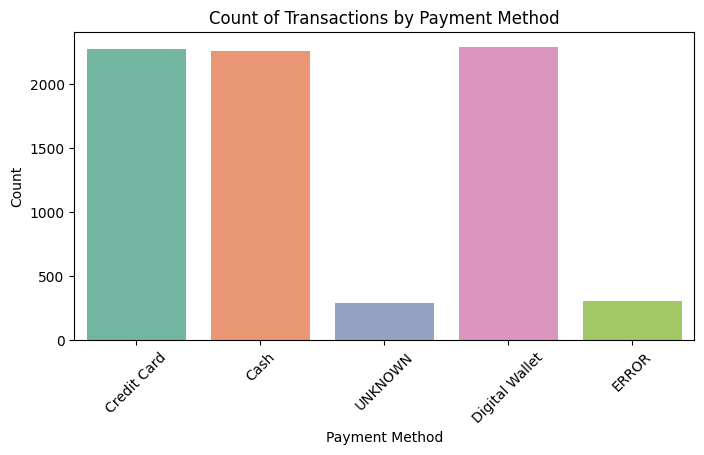

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Payment Method', palette='Set2')
plt.title('Count of Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Scale numerical feature columns
df_clean[num_cols] = scaler.fit_transform(df_clean[num_cols])

print("Numerical columns scaled successfully!")

Numerical columns scaled successfully!


In [ ]:
# Final shape check
print("Final Shape:", df_clean.shape)
print("Remaining Missing Values:", df_clean.isnull().sum().sum())

# Save to CSV
df_clean.to_csv('cleaned_cafe_sales.csv', index=False)
print("Saved successfully as 'cleaned_cafe_sales.csv'.")

Final Shape: (10000, 21)
Remaining Missing Values: 159
Saved successfully as 'cleaned_cafe_sales.csv'.
